Saving movies.csv to movies (5).csv
Saving ratings.csv to ratings (5).csv
userId         int64
movieId        int64
rating       float64
timestamp      int64
dtype: object
movieId     int64
title      object
genres     object
dtype: object
100836
610
9724
9742


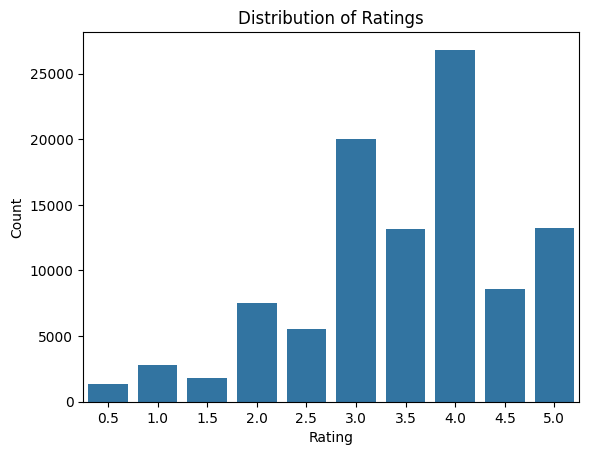

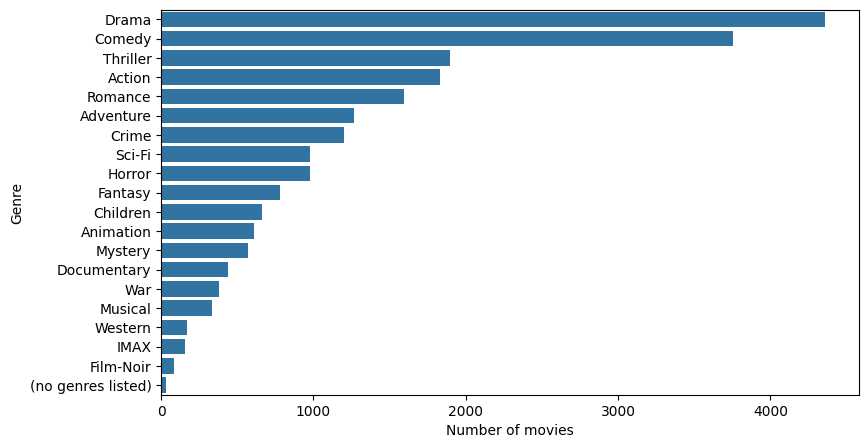

SVD Evaluation: 
RMSE: 0.8807
MAE:  0.6766
Precision:  0.8095358863809282
Recall:  0.328665568369028
KNN Evaluation: 
RMSE: 0.9800
MAE:  0.7615
Precision: 0.7576342012214722
Recall:  0.24268945634266886


In [9]:
from google.colab import files
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
!pip install scikit-surprise -q
from surprise import Dataset, Reader, SVD, accuracy
from surprise.model_selection import train_test_split
from sklearn.metrics import precision_score, recall_score
from surprise import KNNBasic
from sklearn.feature_extraction.text import TfidfVectorizer
from sklearn.metrics.pairwise import cosine_similarity

# Tải dataset lên và đọc dữ liệu
uploaded = files.upload()
ratings = pd.read_csv('ratings.csv')
movies = pd.read_csv('movies.csv')

# Tiến xử lí dữ liệu
print(ratings.dtypes)
print(movies.dtypes)

# Phân tích dữ liệu
print(ratings.shape[0])
print(ratings['userId'].nunique())
print(ratings['movieId'].nunique())
print(movies.shape[0])
ratings['rating'].describe()

# Phân hóa chấm điểm
sns.countplot(data=ratings, x='rating')
plt.xlabel('Rating')
plt.ylabel('Count')
plt.title('Distribution of Ratings')
plt.show

# Phân hóa thể loại
genre_count = movies['genres'].str.split('|').explode().value_counts()
plt.figure(figsize=(9,5))
sns.barplot(x=genre_count.values, y=genre_count.index)
plt.xlabel('Number of movies')
plt.ylabel('Genre')
plt.show()

# SVD
reader = Reader(rating_scale=(0.5, 5.0))
data = Dataset.load_from_df(ratings[['userId', 'movieId', 'rating']], reader)
trainset, testset = train_test_split(data, test_size=0.2, random_state=42)
svd = SVD(random_state=42)
svd.fit(trainset)
prediction = svd.test(testset)
print("SVD Evaluation: ")
accuracy.rmse(prediction)
accuracy.mae(prediction)

y_true = [p.r_ui >= 4 for p in prediction]
y_pred = [p.est >= 4 for p in prediction]
print("Precision: ", precision_score(y_true, y_pred))
print("Recall: ", recall_score(y_true, y_pred))

# KNN
knn = KNNBasic(sim_options={'name': 'cosine', 'user_based': False}, verbose=False)
knn.fit(trainset)
knn_prediction = knn.test(testset)
print("KNN Evaluation: ")
accuracy.rmse(knn_prediction)
accuracy.mae(knn_prediction)
y_true = [p.r_ui >= 4 for p in knn_prediction]
y_pred = [p.est >= 4 for p in knn_prediction]
print("Precision:", precision_score(y_true, y_pred))
print("Recall: ", recall_score(y_true, y_pred))

# TF IDF và Cosine Similarity
movies['genres'] = movies['genres'].str.replace('|', ' ', regex=False)
tf_idf = TfidfVectorizer()
tfidf_matrix = tf_idf.fit_transform(movies['genres'])
similarity = cosine_similarity(tfidf_matrix)
